# Bonus B3: How to build and run an agent with Google ADK

**Notebook 1 of 2: meet ADK on everyday questions**

## Goal

Meet Google's Agent Development Kit (ADK) on questions from an ordinary day: a weekend in Amman, the weather, the
time in Tokyo, a surprise trip. We start from one plain model call and add ADK's four objects one at a time: `Agent`,
`Runner`, `Session` and `Event`. Then we give the agent a Python function as a tool and read the run as a list of
events: the model's function call, our function's response, the answer. After that we keep an agent in a file,
run it from the terminal with `adk run`, run two steps in a fixed order with a `Workflow`, and inspect both in the
browser with `adk web`. This notebook is the playground and does not use the Chinook music shop's data; notebook 2
takes ADK to the Chinook support desk.

## What you will learn

- What `Agent`, `Runner`, `Session` and `Event` each add to a plain model call.
- How to send a message to an ADK agent and read the reply from the parts of an event.
- How a session keeps a conversation, and what a new session does not have.
- How to give an agent a Python function as a tool, and read the function-call and function-response events of a
  run.
- How to keep an agent in a file, run it from the terminal with `adk run` and inspect it in the browser with
  `adk web`.
- How a `Workflow` runs steps in an order that our code sets, and how a step can be a function or an agent.

## Setup

This lab has its own environment. Create it as the README in this folder says, and choose this folder's `.venv` as
the notebook's kernel.

The first cell is the same in every lab: it finds the repository folder, reads the model name from `models.env`, and
takes the key from `.env` without printing it (lab 00 explains it line by line).

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


The setup cell also prints the reasoning effort from `models.env`. This lab does not pass that setting to
ADK, so the agents run at the model's default effort.

---

## Part A: One plain model call, and the work it leaves to our code

We start without ADK. The plain OpenAI client sends one request to the model and gets one reply back.

- `input` is our message.
- `response.output_text` is the text of the reply.

In [2]:
from openai import OpenAI

client = OpenAI()

response = client.responses.create(
    model=MODEL,
    input="I'm spending the weekend in Amman. Suggest one thing to do, in one sentence.",
)

print(response.output_text)

Visit Amman’s Citadel for sweeping views of the city and a glimpse of its Roman, Byzantine, and Umayyad history.


One request, one suggestion. Now a second call that depends on the first:

In [3]:
response = client.responses.create(
    model=MODEL,
    input="Which city did I say I was visiting?",
)

print(response.output_text)

You haven’t mentioned a city in this conversation.


The model answers that we have not mentioned a city in this conversation.

**Notice:** nothing connects the two calls. A request holds only what we put in it, and the second request held
one sentence. To continue a conversation with plain calls, our code has to keep the earlier messages and send them
again. To let the model use a tool, our code has to run the tool and call the model once more. An agent framework
is that code, written once.

ADK gives each of those jobs to an object:

| Job | With plain calls | In ADK |
|---|---|---|
| Hold the instructions, the model and the tools | our variables | `Agent` |
| Keep the conversation between calls | a list we keep and resend | `Session` |
| Call the model, run the tools, repeat until there is an answer | a loop we write | `Runner` |
| Show each step as it happens | our `print` lines | `Event` |

The picture shows one run, with a weather function that we write in Part C. Light green is our own code, the dark
box is the model, white and grey are ADK.

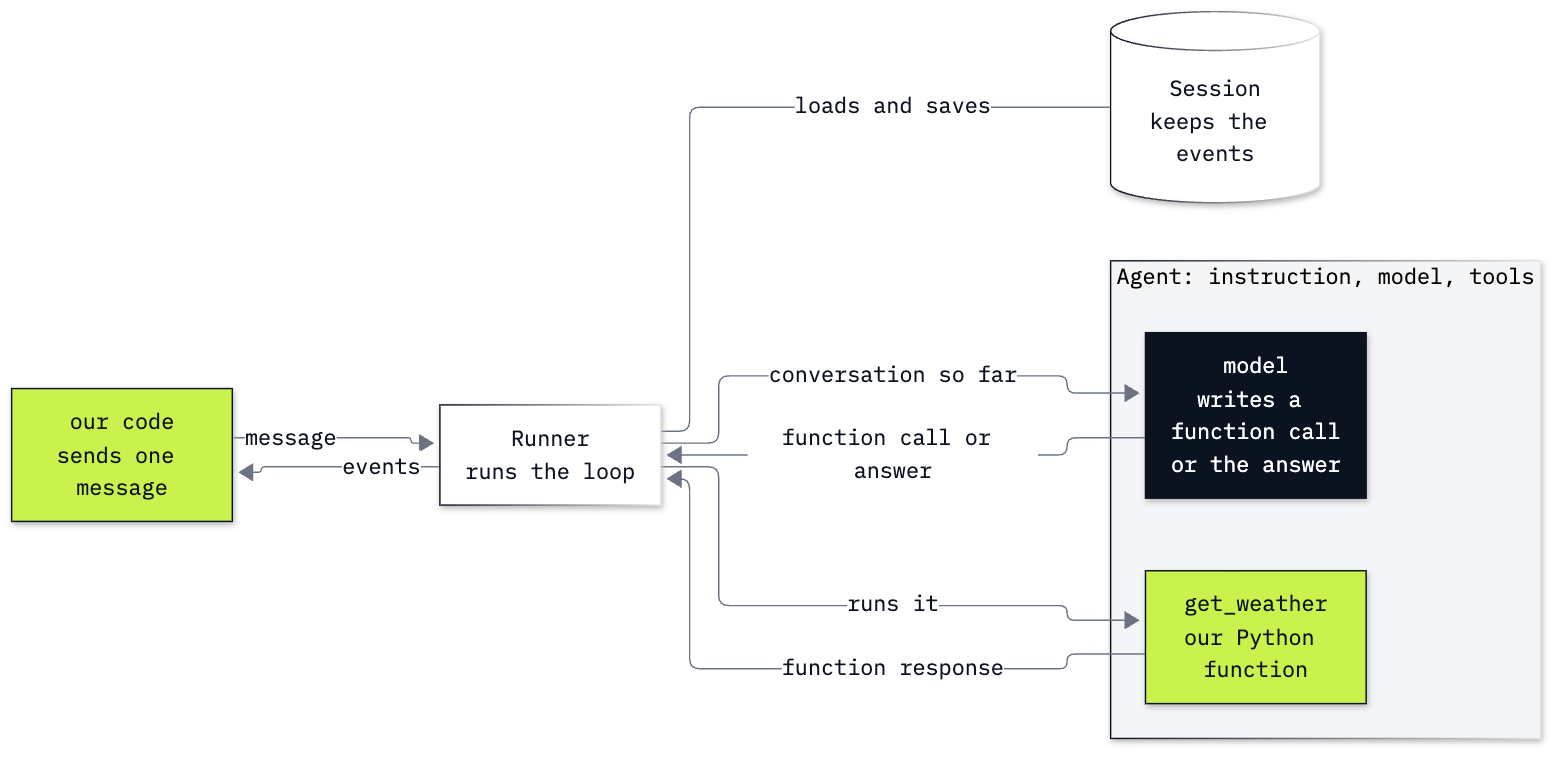

In [4]:
from IPython.display import Image

Image(filename="resources/adk_runner_and_events.png", width=760)

**Checkpoint A.** The first call suggests something to do in Amman. The second call cannot name the city.

---

## Part B: Meet `Agent`, `Runner`, `Session` and `Event`, one at a time

We ask the same two questions again, this time through ADK, and stop at each object on the way.

### `Agent`: the instruction and the model in one object

An `Agent` holds what stays the same from one question to the next:

- `name`: a label. It appears on every event the agent writes.
- `model`: the model that writes the replies.
- `instruction`: the system prompt.

**Which model?** ADK comes from Google, and it is not tied to Google's models. For a Gemini model, `model` is the
model's name as a string. For another vendor's model, `model` is a small object that sends the requests to that vendor's API.
`OpenAIResponsesLlm` is ADK's own class for OpenAI models: it sends each request to OpenAI's Responses API, the API
we called in Part A. Every agent in this lab uses it, except the one in the optional Part G, so the lab runs with the OpenAI key
alone.

In [5]:
from google.adk.agents import Agent
from google.adk.integrations.openai import OpenAIResponsesLlm

llm = OpenAIResponsesLlm(model=MODEL)

assistant = Agent(
    name="assistant",
    model=llm,
    instruction="You are a friendly travel helper. Answer in one or two sentences.",
)

print("name:       ", assistant.name)
print("model:      ", type(assistant.model).__name__, "->", assistant.model.model)
print("instruction:", assistant.instruction)

name:        assistant
model:       OpenAIResponsesLlm -> gpt-6-luna
instruction: You are a friendly travel helper. Answer in one or two sentences.


Creating the agent sent nothing to the model. An `Agent` is only a description: the name, an
`OpenAIResponsesLlm` object that holds the model name from `models.env`, and the instruction.

### `Runner`: the object that runs the agent

An agent cannot run itself. A `Runner` takes one message, calls the model, runs any tools the model asks for, and
repeats until there is an answer. `InMemoryRunner` is the simplest runner: it keeps everything in this Python
process, which is what we want in a playground.

`app_name` is a label for our application. ADK stores every conversation under an application name and a user.

In [6]:
from google.adk.runners import InMemoryRunner

runner = InMemoryRunner(agent=assistant, app_name="playground")

print("app name:       ", runner.app_name)
print("session service:", type(runner.session_service).__name__)

app name:        playground
session service: InMemorySessionService


The runner came with a **session service**, the part of ADK that stores conversations. Here it is an
`InMemorySessionService`.

### `Session`: one conversation

A `Session` is one conversation of one user. ADK will not run an agent without one, so we create it first.

**Why `await`?** `create_session` is an `async` function. Calling it only prepares the work; `await` runs it and
waits for the result. A notebook lets us write `await` directly in a cell.

In [7]:
session = await runner.session_service.create_session(app_name="playground", user_id="student")

print("user:  ", session.user_id)
print("state: ", session.state)
print("events:", len(session.events))

user:   student
state:  {}
events: 0


A new session is empty: no state and no events. `state` is a dictionary where an agent or a tool can keep values
for the conversation; we do not use it in this lab. `session.id` is a random id that ADK made for it; we pass it to
the runner, which uses it to find the conversation to continue.

### The message: a `Content` made of parts

ADK does not take a plain string. A message is a `types.Content` object. (`types` comes from `google-genai`,
Google's model client, which ADK installs and uses for its messages.)

- `role` says who is speaking. Ours is `"user"`.
- `parts` is a list, because one message can hold several pieces: text, a function call, a function's response.
  Ours has one text part.

In [8]:
from google.genai import types

message = types.Content(
    role="user",
    parts=[types.Part(text="I'm spending the weekend in Amman. Suggest one thing to do, in one sentence.")],
)

print(message.role)
print(message.parts[0].text)

user
I'm spending the weekend in Amman. Suggest one thing to do, in one sentence.


### `Event`: one step of a run

`runner.run_async(...)` runs the agent on our message. It does not return one answer at the end. It hands us an
**event** for every step, as the step happens.

**Why `async for`?** It is a `for` loop that waits for the next item. Each time the runner finishes a step, the
loop body runs once with that step's event. We keep the events in a list so we can read them afterwards.

In [9]:
events = []

async for event in runner.run_async(user_id="student", session_id=session.id, new_message=message):
    events.append(event)

print("events:", len(events))

events: 1


One question, one event.

We look inside the event:

- `event.author` is who wrote it: the agent's name.
- `event.is_final_response()` is `True` when this event is the answer to the user.
- `event.content.parts` is the same kind of list as in our message.

In [10]:
event = events[0]

print("author:", event.author)
print("final: ", event.is_final_response())

for part in event.content.parts:
    print("part:  ", "thought" if part.thought else "text", "|", part.text)

author: assistant
final:  True
part:   thought | None
part:   text | Visit the Amman Citadel for sweeping city views and a glimpse of the city’s ancient history.


The author is `assistant`, and the event is final: it is the answer. In our run it has two parts:

- **A thought.** This is the model's reasoning before it answered. OpenAI sends it back in a form we cannot read,
  so its text is `None`.
- **The text of the reply:** another suggestion to visit the Citadel.

This reply starts with a thought part. Not every reply has one, so we cannot take the answer from a fixed position
such as `parts[0]`.

We will read replies many times, so we put that in a small function. `reply_text` joins the text parts of an event
and leaves out any thought part.

In [11]:
def reply_text(event):
    """The text of an event: its text parts joined, leaving out the model's thoughts."""
    return "".join(part.text for part in event.content.parts if part.text and not part.thought)


print(reply_text(events[0]))

Visit the Amman Citadel for sweeping city views and a glimpse of the city’s ancient history.


### The same session keeps the conversation

Sending a message takes the same lines every time: build the `Content`, loop over the events, keep them. We wrap
those lines in one function, `ask`, which returns the events of a run. One thing is new: the function uses `async for`, so it is
defined with `async def`, and we call it with `await`, as we did `create_session`.

Now the question that failed in Part A, asked in the same session:

In [12]:
async def ask(runner, session, text):
    """Send one user message in a session and return the events of the run."""
    message = types.Content(role="user", parts=[types.Part(text=text)])
    events = []
    async for event in runner.run_async(user_id=session.user_id, session_id=session.id, new_message=message):
        events.append(event)
    return events


events = await ask(runner, session, "Which city did I say I was visiting?")

print(reply_text(events[-1]))

You said you’re spending the weekend in Amman.


This time the reply names Amman.

We passed the same `session`, and the runner did the work we listed in Part A: before calling the model it loaded
the session's earlier events, and it saved each new event as it was produced. To see what the session holds now,
we read it back from the session service. (Our `session` variable is the copy we got when we created it, and it
still shows no events.)

In [13]:
stored = await runner.session_service.get_session(app_name="playground", user_id="student", session_id=session.id)

for event in stored.events:
    print(f"{event.author:9} | {reply_text(event)}")

user      | I'm spending the weekend in Amman. Suggest one thing to do, in one sentence.
assistant | Visit the Amman Citadel for sweeping city views and a glimpse of the city’s ancient history.
user      | Which city did I say I was visiting?
assistant | You said you’re spending the weekend in Amman.


Four events, in order: our first message, the assistant's suggestion, our follow-up and its answer. Our own
messages are stored as events too, with the author `user`. When the follow-up ran, the model received the first two
events before the new question, which is how the reply could name the city.

A different session is a different conversation. Same agent, same runner, same question, in a new session:

In [14]:
new_session = await runner.session_service.create_session(app_name="playground", user_id="student")

events = await ask(runner, new_session, "Which city did I say I was visiting?")

print(reply_text(events[-1]))

You haven’t mentioned which city you’re visiting.


The reply says we have not mentioned a city. The agent is the same. The new session held no earlier events, so the
model received the question alone.

**Important:** these sessions are kept in the memory of this Python process. Restart the kernel and they are gone. That is fine for
a playground. Notebook 2 keeps a session in a file.

**Checkpoint B.** Creating the agent sends nothing. One question gives one event, written by `assistant` and marked
final. In the same session the follow-up names Amman, and the session holds four events. In a new session the same
follow-up cannot name the city.

---

## Part C: Give the agent a tool and read the events of a run

Next, a question about the present moment:

> What's the weather in Amman right now? Should I go for a walk?

A model can only write from two things: its training data and what we put in the request. Today's weather is in
neither. We ask our tool-less `assistant` first.

In [15]:
QUESTION = "What's the weather in Amman right now? Should I go for a walk?"

events = await ask(runner, new_session, QUESTION)

print(reply_text(events[-1]))

I can’t access live weather for Amman right now. Check the current temperature, rain, and air quality; if it’s dry and comfortable, a walk sounds good.


The assistant says it cannot access Amman's live weather, and tells us what to check ourselves: the temperature,
the rain and the air quality.

**Notice:** the model did not invent a temperature. It has no way to look one up, and it said so. To answer, it
needs something that can fetch the weather, and that has to be our code.

### A plain Python function that gets the weather

`get_weather` is ordinary Python. It calls [Open-Meteo](https://open-meteo.com/), a free weather service that needs
no key, in two steps:

1. **Find the city.** The geocoding address turns a name (`Amman`) into a latitude and a longitude.
2. **Get the conditions.** The forecast address takes those two numbers and returns the current temperature, the
   temperature it feels like, the rain and the wind.

The first line of the function prints a message every time it runs. That print is how we will know that a tool
really ran.

The last line builds a dictionary and returns it as a **string** (`str(...)`), because a tool's result goes to
the model as text. Inside the dictionary, `**weather.json()["current"]` copies the weather fields next to the city
and the country. A tool may also return the dictionary itself; the tools in Part D do.

In [16]:
import requests


def get_weather(city: str) -> str:
    """Get current weather for a city using Open-Meteo."""
    print(f"🌤️ TOOL CALLED: get_weather({city})")

    # 1. Find the city's coordinates
    geo = requests.get(
        "https://geocoding-api.open-meteo.com/v1/search",
        params={"name": city, "count": 1},
        timeout=10,
    )
    locations = geo.json().get("results", [])
    if not locations:
        return f"City not found: {city}"
    location = locations[0]

    # 2. Get the current weather at those coordinates
    weather = requests.get(
        "https://api.open-meteo.com/v1/forecast",
        params={
            "latitude": location["latitude"],
            "longitude": location["longitude"],
            "current": "temperature_2m,apparent_temperature,precipitation,wind_speed_10m",
        },
        timeout=10,
    )

    return str({"city": location["name"], "country": location["country"], **weather.json()["current"]})

Before any model is involved, we call the function ourselves. If it does not work here, no agent can make it work.

In [17]:
print(get_weather("Amman"))

🌤️ TOOL CALLED: get_weather(Amman)


{'city': 'Amman', 'country': 'Jordan', 'time': '2026-11-11T03:45', 'interval': 900, 'temperature_2m': 7.1, 'apparent_temperature': 3.9, 'precipitation': 0.0, 'wind_speed_10m': 5.6}


First the `TOOL CALLED` line, then the result. When we ran it, Amman was at 7.1 °C and felt like 3.9 °C, with no
rain and a wind of 5.6 km/h.

| Field | What it holds |
|---|---|
| `temperature_2m` | the air temperature in °C, two metres above the ground |
| `apparent_temperature` | what it feels like, in °C |
| `precipitation` | rain in millimetres |
| `wind_speed_10m` | the wind in km/h |
| `time` | when the reading was taken, in GMT, not in the city's local time |
| `interval` | the seconds one reading covers (900 is 15 minutes) |

### The function as a tool

**Important:** the model never sees our Python. It gets a description of the function: its name, what it is for,
and its arguments. ADK writes that description from the function itself. `FunctionTool` wraps a function, and we
can read what it took from ours:

In [18]:
from google.adk.tools import FunctionTool

weather_tool = FunctionTool(get_weather)

print("name:       ", weather_tool.name)
print("description:", weather_tool.description)

name:        get_weather
description: Get current weather for a city using Open-Meteo.


The name is the function's name, and the description is its docstring. The argument comes from the type hint
(`city: str`), which is not printed here. This is why a tool function needs a clear name, a docstring and type hints: they are the only
information the model gets about the function when it chooses a tool.

We do not have to wrap the function ourselves. When we put a plain function in `tools=[...]`, the agent makes the
`FunctionTool` for us.

### The weather agent

A new agent with the same model object, an instruction that mentions the tool, and `tools=[get_weather]`. A new
agent needs its own runner, and we start a new session for it.

In [19]:
weather_agent = Agent(
    name="weather_agent",
    model=llm,
    instruction=(
        "You are a friendly weather reporter. "
        "Always use get_weather for current conditions. "
        "Keep your reports short and fun."
    ),
    tools=[get_weather],
)

weather_runner = InMemoryRunner(agent=weather_agent, app_name="playground")
weather_session = await weather_runner.session_service.create_session(app_name="playground", user_id="student")

events = await ask(weather_runner, weather_session, QUESTION)

print(reply_text(events[-1]))

🌤️ TOOL CALLED: get_weather(Amman)


Amman is **7°C, but feels like 4°C**—dry with a light breeze. A walk sounds good if you bundle up! It’s around **3:45 a.m.** there, though, so maybe wait for daylight. 🌙🧥


`TOOL CALLED` is printed: ADK ran our function. The reply has real numbers now: 7 °C, feeling like 4 °C, and dry. We wrote no loop and no description of the function.

### Read the run event by event

A right answer does not tell us how it was reached. The events do. Two methods read what an event carries:

- `event.get_function_calls()` returns the function calls the model wrote in this event.
- `event.get_function_responses()` returns the results our functions gave back.

We print one line for each thing we find, with the event's number in front.

In [20]:
for number, event in enumerate(events, start=1):
    for call in event.get_function_calls():
        print(number, "function call    :", call.name, call.args)
    for response in event.get_function_responses():
        print(number, "function response:", response.name, response.response)
    if event.is_final_response():
        print(number, "final answer     :", reply_text(event))

1 function call    : get_weather {'city': 'Amman'}
2 function response: get_weather {'result': "{'city': 'Amman', 'country': 'Jordan', 'time': '2026-11-11T03:45', 'interval': 900, 'temperature_2m': 7.1, 'apparent_temperature': 3.9, 'precipitation': 0.0, 'wind_speed_10m': 5.6}"}
3 final answer     : Amman is **7°C, but feels like 4°C**—dry with a light breeze. A walk sounds good if you bundle up! It’s around **3:45 a.m.** there, though, so maybe wait for daylight. 🌙🧥


Three events:

1. **A function call.** The model wrote the name `get_weather` and the arguments `{'city': 'Amman'}`. `call.args`
   is a Python dictionary, ready to use.
2. **A function response.** ADK ran `get_weather(city='Amman')`, which is when `TOOL CALLED` printed. Our function
   returned a string, and ADK put it in a dictionary under the key `result`. The temperature in it is 7.1, the same
   reading as in our own call; the reply rounds it to 7.
3. **The final answer,** which the model wrote from that response.

These are the arrows of the picture in Part A: function call, runs it, function response.

**Notice** one mistake in the reply: *around 3:45 a.m. there*. The model took that from the `time` field, which
is in GMT. The local time in Amman was 06:45 (Part D prints it). The model writes its answer from what a tool
returns, and nothing in this field says GMT. A tool for an agent should return values that need no guessing.

**Key lesson:** the model writes the function call, and ADK runs the function. A function call is a request written by the model: a name and
arguments. Nothing has run at that point. The runner finds the Python function with that name, calls it, and puts
the return value in a function-response event, which goes back to the model with the rest of the conversation.

How many times was the model called? An event that came from the model carries `usage_metadata`, the token counts
of that model call. An event our function produced has none.

In [21]:
for number, event in enumerate(events, start=1):
    usage = event.usage_metadata
    print(number, "input tokens:", usage.prompt_token_count if usage else None)

1 input tokens: 111
2 input tokens: None
3 input tokens: 218


Three events, two model calls. Events 1 and 3 came from the model, with 111 and 218 input tokens. Event 2 shows
`None`: our function produced it. The second model call is the larger one because it carries the conversation so
far, including the function call and its response. So the number of events in a run is not the number of model
calls.

### A follow-up question that compares two cities

Before you run the next cell: we ask about Tokyo and which of the two cities is warmer. How many function calls
will there be, and for which cities?

In [22]:
events = await ask(weather_runner, weather_session, "And in Tokyo? Which of the two is warmer right now?")

for number, event in enumerate(events, start=1):
    for call in event.get_function_calls():
        print(number, "function call    :", call.name, call.args)
    for response in event.get_function_responses():
        print(number, "function response:", response.name, response.response)
    if event.is_final_response():
        print(number, "final answer     :", reply_text(event))

🌤️ TOOL CALLED: get_weather(Tokyo)


1 function call    : get_weather {'city': 'Tokyo'}
2 function response: get_weather {'result': "{'city': 'Tokyo', 'country': 'Japan', 'time': '2026-11-11T03:45', 'interval': 900, 'temperature_2m': 13.7, 'apparent_temperature': 11.4, 'precipitation': 0.0, 'wind_speed_10m': 4.6}"}
3 final answer     : Tokyo is **13.7°C** (feels like **11.4°C**), dry with a light breeze. **Tokyo is warmer** than Amman by about **6.6°C** right now. 🌤️


One function call, for Tokyo only. The model did not ask for Amman again. We asked in the same session, so the
request already held Amman's function response from the run before, and the model compared Tokyo's reading with
it: Tokyo 13.7 °C, warmer than Amman by about 6.6 °C.

**Checkpoint C.** Without a tool the assistant cannot report Amman's weather. With `tools=[get_weather]` the run
has three events: a function call for `get_weather` with `{'city': 'Amman'}`, the function response with the
weather, and the final answer. `TOOL CALLED` prints once. Your numbers are today's, so they differ from ours.

---

## Part D: Keep an agent in a file and run it from the terminal

So far we defined our agents in this notebook's cells. An agent we want to keep goes in a file. ADK expects one folder per
agent:

```
my_agent/
    city_buddy/
        __init__.py     one line: from . import agent as agent
        agent.py        the agent, in a variable named root_agent
```

This lab comes with `my_agent/city_buddy/`: the weather agent of Part C with a second tool, the local time in any
city. We print its `agent.py`:

In [23]:
print(Path("my_agent/city_buddy/agent.py").read_text())

from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo

import requests
from dotenv import dotenv_values
from google.adk.agents import Agent
from google.adk.integrations.openai import OpenAIResponsesLlm

# The model name comes from models.env at the repository folder
ROOT = next(p for p in Path(__file__).resolve().parents if (p / "models.env").exists())
MODEL = dotenv_values(ROOT / "models.env")["MODEL_DEFAULT"]


def find_city(city: str) -> dict | None:
    """Look a city up in Open-Meteo: its name, country, coordinates and time zone."""
    geo = requests.get(
        "https://geocoding-api.open-meteo.com/v1/search",
        params={"name": city, "count": 1},
        timeout=10,
    )
    locations = geo.json().get("results", [])
    return locations[0] if locations else None


def get_weather(city: str) -> dict:
    """Get the current weather in a city."""
    location = find_city(city)
    if not location:
        return {"status": "error", "message": 

Read the file from the top:

- **The two lines under the first comment** find the repository folder and read the model name from `models.env`,
  as this notebook's setup cell does. A file cannot use the notebook's variables, so it reads the setting itself.
- **`find_city`** is the first half of Part C's `get_weather` (find the city), moved into a function of its own
  because both tools need it. It returns the city's record, or `None` when Open-Meteo finds no such city;
  `dict | None` in its first line says so.
  Open-Meteo's answer for a city holds its coordinates and also its time zone.
- **`get_weather`** is Part C's function in a shorter form: it calls `find_city`, has no `TOOL CALLED` print, and
  returns a dictionary with a `status`. For a
  city Open-Meteo cannot find, the dictionary says `status: error` with a message, and the model can pass that
  message on to the user. ADK accepts both kinds of return value: it puts a string under the key `result`
  (Part C, event 2) and passes a dictionary on as it is.
- **`get_local_time`** takes the city's time zone (`location["timezone"]`, for example `Asia/Amman`) and asks
  Python for the time there with `datetime.now(ZoneInfo(...))`. It works for any city Open-Meteo can find.
- **`root_agent`** is the agent, with both functions in `tools`. `description` is one sentence about the agent,
  for people and for other agents that may pass it a question; `instruction` is what its own model reads. The
  name of the variable matters: `adk run` and `adk web` open
  `agent.py` and look for a variable called `root_agent`.

As in Part C, we call the functions ourselves before any model is involved: first `find_city`, to see the time
zone in Open-Meteo's record, then `get_local_time`.

In [24]:
from my_agent.city_buddy.agent import find_city, get_local_time

print(find_city("Amman")["timezone"])
print(get_local_time("Amman"))

Asia/Amman


{'status': 'success', 'city': 'Amman', 'day': 'Wednesday', 'time': '06:45'}


`Asia/Amman` is the time zone in Open-Meteo's record for the city. `get_local_time` returns a dictionary with the
day (`%A` in the code is the weekday's name) and the time (`%H:%M`, on a 24-hour clock): Wednesday, 06:45 when we
ran it.

### `adk run`: the agent in the terminal

Installing ADK also installs a command, `adk`. In a terminal, in this lab's folder, we would type
`uv run adk run my_agent/city_buddy` followed by a question in quotes. (`uv run` starts a command in this lab's
environment. With the environment activated, type `adk run ...` alone.)

From a notebook we start the same program with Python's `subprocess.run`, which runs a command and gives us what
it printed:

- The command is a list: this kernel's Python (`sys.executable`), then `-m google.adk.cli`, which is what the
  `adk` command runs, then `run`, the agent's folder and the question.
- `capture_output=True, text=True` gives us what the command printed, as text, in `result.stdout`.
- `adk run` starts with two lines about its log file. The loop prints every line except those two.

If the cell prints nothing, run the command in a terminal to read its error.

In [25]:
import subprocess
import sys

TRIP_QUESTION = "I'm in Amman and my friend is in Tokyo. What time is it for each of us, and what's the weather like?"

# The same program as the adk command, started with this notebook's Python
result = subprocess.run(
    [sys.executable, "-m", "google.adk.cli", "run", "my_agent/city_buddy", TRIP_QUESTION],
    capture_output=True,
    text=True,
)

# adk run first prints two lines about its log file; we print the rest
for line in result.stdout.splitlines():
    if not line.startswith(("Log setup", "To access latest log")):
        print(line)

[city_buddy]: - **Amman:** Wednesday, 06:46 — 7°C, feels like 4°C; dry, with light winds.
- **Tokyo:** Wednesday, 12:46 — 14°C, feels like 11°C; dry, with light winds.


Two lines, the first with the agent's name in brackets in front: the time and the weather in Amman and in Tokyo
(ours: 06:46 and 7 °C in Amman, 12:46 and 14 °C in Tokyo). `adk run` prints the agent's replies only.
The function calls behind this reply are not shown here; Part F shows where to see them.

Without a question at the end, `adk run my_agent/city_buddy` opens a chat in the terminal: type a message, read
the reply, and type `exit` to leave.

**Checkpoint D.** The file prints with `find_city`, `get_weather`, `get_local_time` and `root_agent`. Called by
hand, `find_city` gives `Asia/Amman` and `get_local_time` gives a dictionary with the day and the time. `adk run`
answers with the time and the weather in both cities; its first line starts with `[city_buddy]`.

---

## Part E: Run steps in a fixed order with a `Workflow`

In every run so far, the model chose the steps: whether to call a function, which one, and when to answer.
Sometimes we know the steps in advance and want them in the same order every time. ADK's `Workflow` is for that.
The second folder in `my_agent/`, `surprise_trip/`, holds a small `Workflow`: send it any message, and it picks a
city for us and suggests one thing to do there.

In [26]:
print(Path("my_agent/surprise_trip/agent.py").read_text())

import random
from pathlib import Path

from dotenv import dotenv_values
from google.adk.agents import Agent
from google.adk.integrations.openai import OpenAIResponsesLlm
from google.adk.workflow import START, Workflow

# The model name comes from models.env at the repository folder
ROOT = next(p for p in Path(__file__).resolve().parents if (p / "models.env").exists())
MODEL = dotenv_values(ROOT / "models.env")["MODEL_DEFAULT"]

CITIES = ["Amman", "Cape Town", "Kyoto", "Marrakesh", "Mexico City", "Reykjavik"]


def pick_city() -> str:
    """Pick the destination at random."""
    return random.choice(CITIES)


plan_agent = Agent(
    name="plan_agent",
    model=OpenAIResponsesLlm(model=MODEL),
    instruction=(
        "You get the name of a city. Name the city, then suggest one thing "
        "to do there on a free afternoon, in a single sentence."
    ),
)

root_agent = Workflow(
    name="surprise_trip",
    edges=[(START, pick_city, plan_agent)],
)



Two steps, and a `Workflow` that connects them:

- **`pick_city` is a plain Python function.** It picks one of six cities with `random.choice`. No model is
  involved.
- **`plan_agent` is an ordinary agent** with no tools. It gets the name of a city and suggests one thing to do
  there.
- **`edges=[(START, pick_city, plan_agent)]` is the order.** The tuple is one chain, read from left to right:
  `START`, ADK's marker for where a run begins, then the function, then the agent. `edges` is a list because a
  workflow can have several chains; ours has one. A step of a workflow can be a function or an agent. Each step receives only what the step before it returned. That
  is why the instruction of `plan_agent` says *Name the city*: a step added after `plan_agent` would receive only
  the sentence `plan_agent` wrote.

**Why is the first step a function?** Picking at random is a job for code. A model that is asked for a random city
tends to name the same few cities again and again (the README has our count). `random.choice` gives every city in
the list the same chance.

Here `root_agent` is the `Workflow`. A runner accepts a `Workflow` in the place of an agent, so we can import it
and run it with the `ask` function from Part B. Any message starts it; we send *go*. No step reads the word itself:
`pick_city` takes no argument.

One thing is new when we read the events. A function step has no reply from a model, so its event has no
`content`. What the function returned is in `event.output`. For each event we print the author and the text, and
we take the text from `event.output` when there is no `content`.

In [27]:
from my_agent.surprise_trip.agent import root_agent as surprise_trip

trip_runner = InMemoryRunner(agent=surprise_trip, app_name="playground")
trip_session = await trip_runner.session_service.create_session(app_name="playground", user_id="student")

events = await ask(trip_runner, trip_session, "go")

for event in events:
    text = event.output if event.content is None else reply_text(event)
    print(f"{event.author:13} | {text}")

surprise_trip | Marrakesh
plan_agent    | Marrakesh is a city in Morocco; spend a free afternoon wandering the souks of the medina.


Two events, in the order of the edges:

- **The first event is the function's.** Its author is the workflow, `surprise_trip`, and its text is what
  `pick_city` returned: *Marrakesh* in our run. No model call was made for it: like the function response in
  Part C, this event has no `usage_metadata`.
- **The second event is `plan_agent`'s.** It received that one name and suggested an afternoon in the souks of the
  medina.

Run the cell again and the city will probably change. The order of the steps will not: it comes from `edges`, and
no model call chooses it.

| | `city_buddy` | `surprise_trip` |
|---|---|---|
| Who decides the next step | the model, at every model call | our code, in `edges` |
| What the model does | chooses a function, or answers | writes the text of one step |
| Good for | a question whose steps we cannot know in advance | a task whose steps are always the same |

**Checkpoint E.** Two events: the first holds a city from the list, the second is `plan_agent`'s suggestion for
that city.

---

## Part F: Inspect a run in the browser with `adk web`

ADK has a development page that shows what this notebook printed line by line (the events of a run, the function
calls and their arguments, the session) and adds a drawing of the agent. It runs on your own machine.

**Start it.** In a terminal, in this lab's folder (`bonus/B3_Google_ADK`), with this lab's environment:

```bash
uv run adk web my_agent
```

Without `uv`, activate this lab's environment and type `adk web my_agent`. `my_agent` is the folder that holds
the agent folders. The first time you run `adk` in a terminal it asks *Enable telemetry? [Y/n]*; the README in
this folder says what that covers. The command keeps running and prints an address,
`http://127.0.0.1:8000`. Open it in a browser. When you are done, stop the server with `Ctrl+C` in the terminal.

**`city_buddy`.** Choose `city_buddy` in the list at the top left and ask the question from Part D: *I'm in Amman
and my friend is in Tokyo. What time is it for each of us, and what's the weather like?*

![The adk web page for city_buddy. On the right, four numbered events: the question about Amman and Tokyo, an event with four function calls (get_local_time and get_weather for Amman and for Tokyo), an event with their four responses, and the answer with the day, the time and the weather in both cities. On the left, a drawing of city_buddy with arrows to its two tools, get_weather and get_local_time.](resources/adk_web_city_buddy.png)

How to read the page:

- **The right side is the list of events,** numbered. Event 1 is our message. Event 2 holds four function calls:
  `get_local_time` and `get_weather`, each for Amman and for Tokyo. The model asked for all four in one event.
  Event 3 holds the four responses, and event 4 is the answer. They are the same kinds of event we printed in
  Part C: function calls, function responses and the answer.
- **Click an event** (try event 4, the answer). A panel opens on the left with a drawing of the agent:
  `city_buddy` and, under it, its two tools.
- **The *i* icon at the left edge of that panel** shows the selected event's details: its id, its author and when
  it was written.
- **State** shows the session's state, and **New Session** starts an empty conversation, like `create_session` in
  Part B.

Then ask about your own city. The two tools work for any city Open-Meteo can find.

**`surprise_trip`.** Choose `surprise_trip` in the list and type anything, for example *go*.

![The adk web page for surprise_trip. On the right, three events: the user's message go, the text "Cape Town" in quotes, and a suggestion to take the cable car up Table Mountain. On the left, a drawing of the workflow from top to bottom: START, a box marked f pick_city, a box plan_agent, END, connected by arrows.](resources/adk_web_surprise_trip.png)

Click event 3. The drawing is the `edges` list of Part E: `START`, the function `pick_city` (marked *ƒ*), the
agent `plan_agent`, and `END`. We did not write `END`; ADK draws it after the last step. On the right, event 2 is what the function returned, in quotes, and event 3 is the agent's suggestion.
Start a new session and type *go* again: the city will probably be another one.

The screenshots are from other runs of these two agents than the cells above: they show 1:01 a.m. and 10 °C in
Amman, and Cape Town where Part E picked Marrakesh. Your times, your weather and your city will differ too.

⚠️ `adk web` is for development on your own machine. Anyone who can reach its address can talk to your agents, so
do not start it on a shared or public network.

**Checkpoint F.** The page lists `city_buddy` and `surprise_trip`. The question about Amman and Tokyo shows
function calls for both cities and their responses before the answer (ours: four calls in one event). After
you click an event, the workflow's drawing shows `pick_city` and `plan_agent` between `START` and `END`.

---

## Part G (optional): Run the same agent on a Gemini model

ADK was built for Google's Gemini models first. This part runs our weather agent on one.

⚠️ This part needs a second key, `GEMINI_API_KEY`, in `.env`. It is optional: without the key each cell prints a
message and skips, and nothing in notebook 2 depends on it. The Gemini model name is `GEMINI_MODEL` in
`models.env`.

First the plain call, as in Part A, on Google's own client. The package is `google-genai`, which ADK installs.
`interactions.create` sends one request and returns one reply.

In [28]:
GEMINI_KEY = os.environ.get("GEMINI_API_KEY") or local.get("GEMINI_API_KEY")

if not GEMINI_KEY:
    print("No GEMINI_API_KEY in .env: skipping this optional part.")
else:
    from google import genai

    os.environ["GEMINI_API_KEY"] = GEMINI_KEY
    gemini_client = genai.Client()

    interaction = gemini_client.interactions.create(
        model=settings["GEMINI_MODEL"],
        input="I'm spending the weekend in Amman. Suggest one thing to do, in one sentence.",
    )
    print(interaction.output_text)

Wander through the ancient ruins of the Amman Citadel at golden hour, then descend into the bustling downtown markets for a steaming cup of mint tea and authentic kanafeh at Habibah.


Now the agent. For a Gemini model, `model` is the model's name as a string: no model object is needed, because ADK
calls Gemini models directly. The instruction and the tool are the weather agent's.

In [29]:
if not GEMINI_KEY:
    print("No GEMINI_API_KEY in .env: skipping this optional part.")
else:
    gemini_weather = Agent(
        name="gemini_weather_agent",
        model=settings["GEMINI_MODEL"],
        instruction=weather_agent.instruction,
        tools=[get_weather],
    )

    gemini_runner = InMemoryRunner(agent=gemini_weather, app_name="playground")
    gemini_session = await gemini_runner.session_service.create_session(app_name="playground", user_id="student")

    events = await ask(gemini_runner, gemini_session, QUESTION)
    print(reply_text(events[-1]))

🌤️ TOOL CALLED: get_weather(Amman)


Hey there! Over in Amman, it's currently a chilly 7°C (feels more like 4°C with the breeze) and completely dry. 

As for a walk? If you bundle up in a warm coat, hat, and scarf, it could be crisp and refreshing! Just keep in mind it's pretty cold out there, so maybe save the stroll for the afternoon sun if you prefer to stay cozy! 🧣☀️


With the key in place, the first cell prints a one-sentence suggestion from the Gemini model. The second prints
the `TOOL CALLED` line and a weather report in different words (ours gave 7 °C). The tool ran in our Python
exactly as before; this time a Gemini model wrote the function call and the reply. Apart from the agent's name, the only line
that changed is `model`.

---

## What you can do now

- Say what `Agent`, `Runner`, `Session` and `Event` each do, and build a first agent from them (Parts A and B).
- Send a message as a `Content` with parts, and read the reply from an event (Part B).
- Continue a conversation in a session, and explain why a new session starts from nothing (Part B).
- Give an agent a Python function as a tool, and read the function call, the function response and the answer from
  the events of a run (Part C).
- Keep an agent in a file and run it with `adk run` (Part D).
- Run steps in a fixed order with a `Workflow`, with a function or an agent as a step (Part E).
- Open an agent in `adk web` and find its events, its function calls and its drawing (Part F).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `ModuleNotFoundError: No module named 'google.adk'` | the notebook's kernel is not this lab's environment | choose `bonus/B3_Google_ADK/.venv` as the kernel (see the README in this folder) |
| `Error code: 400 - Function tools with reasoning_effort are not supported for gpt-6-luna in /v1/chat/completions. To use function tools, use /v1/responses or set reasoning_effort to 'none'.` | the agent's model was given as a plain OpenAI model name or as `OpenAILlm`, which use OpenAI's Chat Completions API | pass `model=OpenAIResponsesLlm(model=MODEL)` |
| `SessionNotFoundError: Session not found: ...` | the runner was given a `session_id` that its session service does not hold | create the session with `create_session` first, and pass its `id` |
| `City not found: ...` in a function response | Open-Meteo did not recognise the city name | ask with the city's common English name |

## Challenge

1. **Chain two tools.** Write a function `to_fahrenheit(celsius: float) -> float` that returns
   `celsius * 9 / 5 + 32`, rounded to one decimal. Build a weather agent with `tools=[get_weather, to_fahrenheit]`
   and one more line of instruction: always use `to_fahrenheit` to convert a temperature. Ask: *What's the
   temperature in Amman right now, in Fahrenheit?* Print the function calls, the function responses and the answer,
   as in Part C. Expected: two function calls in two separate events, `get_weather` first, and the argument of
   `to_fahrenheit` is the temperature that `get_weather` returned.
2. **Add a third step to the workflow.** Import `pick_city` and `plan_agent` from `my_agent.surprise_trip.agent`,
   and `START` and `Workflow` from `google.adk.workflow`.
   Write a `pack_agent` that gets one sentence about an afternoon in a city and lists three things to pack for
   it. Build a `Workflow` whose edges go from `START` through `pick_city` and `plan_agent` to your new agent, and
   run it. Expected: three events in the order of the edges, and a packing list that suits the afternoon `plan_agent`
   suggested. How did `pack_agent` get the name of the city?

The worked solution, run with its outputs, is in `solved/b3a_meet_google_adk_solution.ipynb`.

## Resources

- [Agent Development Kit](https://adk.dev/): the documentation's home
- [LLM agents](https://adk.dev/agents/llm-agents/): `Agent`, its instruction and its tools
- [Runtime](https://adk.dev/runtime/): the runner and the event loop;
  [the command line](https://adk.dev/runtime/command-line/) and
  [the web interface](https://adk.dev/runtime/web-interface/)
- [Sessions](https://adk.dev/sessions/session/): what a session holds, and the session services
- [Events](https://adk.dev/events/): what an event carries and how to read it
- [Function tools](https://adk.dev/tools-custom/function-tools/): Python functions as tools
- [Workflows](https://adk.dev/workflows/): steps in a fixed order
- [Models](https://adk.dev/agents/models/): Gemini models by name, and other vendors' models
- [Open-Meteo](https://open-meteo.com/en/docs): the weather service `get_weather` calls

Next: [notebook 2, ADK at the Chinook desk](b3b_google_adk_at_the_desk.ipynb).